# Average Monthly Price Forecasting — Next 12 Months

**Candidate:** [YOUR NAME] &nbsp;|&nbsp; **Phone:** [YOUR PHONE] &nbsp;|&nbsp; **Email:** [YOUR EMAIL]

**Dataset:** `price_data.csv` (the only data used) — 249 monthly observations, Jan 2005 – Sep 2025, columns `date` and `avg_monthly_price`.
**Forecast horizon:** Oct 2025 – Sep 2026 (12 months).

### Contents
1. Data loading & cleaning (missing values, outliers, anomalies)
2. Exploratory analysis & model selection rationale
3. Model comparison, tuning and performance (rolling-origin cross-validation + final hold-out)
4. 12-month forecast with prediction intervals
5. Business actions in response to predicted price changes
6. Measuring whether the actions worked
7. Deploying with Django
8. Real-time predictions: Django + FastAPI
9. Frontend integration: Next.js and React Native
10. Production monitoring, drift and retraining

In [1]:
import warnings, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import GradientBoostingRegressor

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
np.random.seed(42)
H = 12   # forecast horizon (months)

## 1. Data loading and cleaning

In [2]:
raw = pd.read_csv("price_data.csv", parse_dates=["date"])
print(raw.shape); print(raw.dtypes); display(raw.head()); display(raw.tail())

# --- structural checks ---
print("\nMissing values:\n", raw.isna().sum().to_string())
print("Duplicate dates:", raw["date"].duplicated().sum())
print("Non-positive prices:", (raw["avg_monthly_price"] <= 0).sum())
full_idx = pd.date_range(raw["date"].min(), raw["date"].max(), freq="MS")
print("Calendar months missing from the index:", len(full_idx.difference(raw["date"])))
print("All dates are month-start:", bool((raw["date"].dt.day == 1).all()))

(249, 2)
date                 datetime64[us]
avg_monthly_price             int64
dtype: object


,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876


,date,avg_monthly_price
244,2025-05-01,14263
245,2025-06-01,14263
246,2025-07-01,16000
247,2025-08-01,15025
248,2025-09-01,15750



Missing values:
 date                 0
avg_monthly_price    0
Duplicate dates: 0
Non-positive prices: 0
Calendar months missing from the index: 0
All dates are month-start: True


The file is structurally clean: no nulls, no duplicate dates, no gaps in the monthly calendar and no non-positive prices.
Even so, I still enforce a regular monthly index (`asfreq("MS")`) and keep an interpolation step in the pipeline so the same code is safe on future data refreshes where gaps may appear.

Gaps filled: 0
count      249.0
mean      7918.9
std       2805.0
min       3500.0
25%       6123.0
50%       7250.0
75%       9783.0
max      16163.0


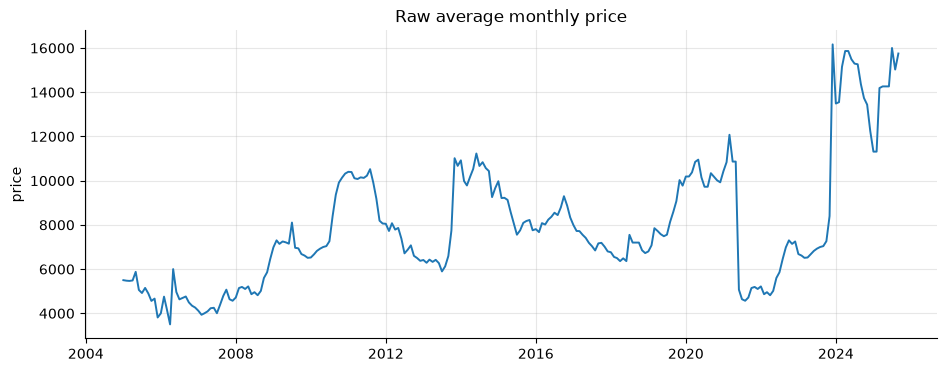

In [3]:
s_raw = raw.set_index("date")["avg_monthly_price"].astype(float).asfreq("MS")
n_gaps = int(s_raw.isna().sum())
s_raw = s_raw.interpolate(method="time")           # no-op today; protects future refreshes
print("Gaps filled:", n_gaps)
print(s_raw.describe().round(1).to_string())

fig, ax = plt.subplots()
ax.plot(s_raw, lw=1.4); ax.set_title("Raw average monthly price"); ax.set_ylabel("price")
plt.show()

### 1.1 Anomaly review
The series is a trending, regime-switching price series rather than a stable one, so I separate **three** kinds of unusual observations because each needs different treatment:

| Type | Definition | Treatment |
|---|---|---|
| **Isolated spike / data glitch** | A single month far from *both* neighbours, which agree with each other (the price goes away and comes back) | Replace by interpolation (it is almost certainly noise) |
| **Level shift (regime change)** | A large jump that *persists* (e.g. Dec 2023) | **Keep** — it is real information; deleting it would hide the very risk we are forecasting |
| **Stale / repeated value** | The same price in consecutive months | Keep, but flag (likely carry-forward of an unchanged quote) |

In [4]:
ls = np.log(s_raw)                                   # work in logs: moves are proportional
r  = ls.diff()                                       # monthly log return

# (a) isolated spikes: deviation from the average of the two neighbours, robust z-score
def detect_spikes(ls, z_thresh=3.5):
    # Flag single-month spikes: far from BOTH neighbours, neighbours agree with each other, and the point is a local extreme.
    dev  = ls - (ls.shift(1) + ls.shift(-1)) / 2
    mad  = 1.4826 * np.median(np.abs(dev.dropna() - dev.median()))
    zdev = (dev - dev.median()) / max(mad, 1e-9)                          # floor avoids divide-by-zero on perfectly smooth series
    is_peak = ((ls - ls.shift(1)) * (ls - ls.shift(-1)) > 0)              # local max/min => it reverts
    nbr_close = (ls.shift(1) - ls.shift(-1)).abs() < dev.abs()           # neighbours agree with each other, the point does not
    return (zdev.abs() > z_thresh) & is_peak & nbr_close, zdev

spike, zdev = detect_spikes(ls)
print("Isolated spikes flagged:", int(spike.sum()))
display(pd.DataFrame({"price": s_raw[spike], "z": zdev[spike].round(1)}))

# (b) persistent level shifts (large move that does NOT revert) -> retained
zr = (r - r.median()) / (1.4826 * np.median(np.abs(r.dropna() - r.median())))
shift = (zr.abs() > 6) & ~spike
print("\nLarge persistent moves (level shifts, retained):")
display(pd.DataFrame({"price": s_raw[shift], "prev": s_raw.shift(1)[shift], "log_return": r[shift].round(3)}))

# (c) repeated values
rep = s_raw.diff().eq(0)
print("Repeated (stale) values:", int(rep.sum()), "->", [d.strftime("%Y-%m") for d in s_raw.index[rep]])

Isolated spikes flagged: 5


,price,z
date,,
2005-05-01,5876.0,3.7
2006-02-01,4755.0,5.1
2006-05-01,6000.0,12.2
2009-07-01,8106.0,4.7
2021-03-01,12075.0,3.6



Large persistent moves (level shifts, retained):


,price,prev,log_return
date,,,
2013-11-01,11016.0,7744.0,0.352
2021-06-01,5070.0,10863.0,-0.762
2023-12-01,16163.0,8400.0,0.654


Repeated (stale) values: 9 -> ['2018-09', '2018-10', '2020-02', '2020-08', '2021-05', '2024-05', '2025-02', '2025-05', '2025-06']


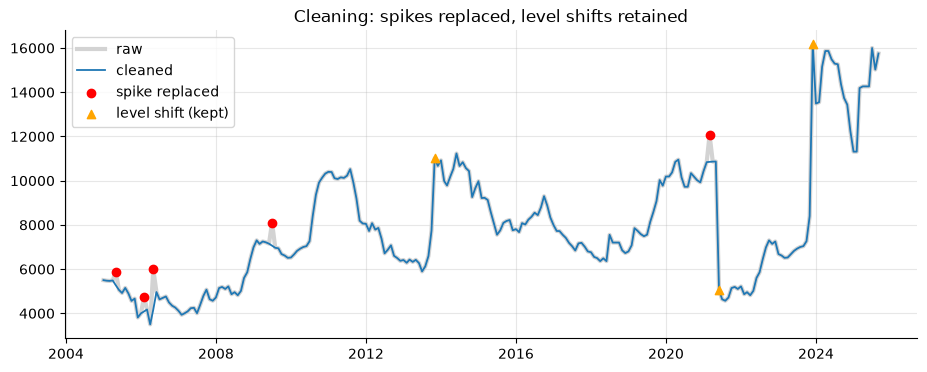

Max abs change from cleaning: 1832


In [5]:
# --- Treatment: replace only isolated spikes by log-linear interpolation between neighbours
ls_clean = ls.copy()
ls_clean[spike] = np.nan
ls_clean = ls_clean.interpolate()
s_clean = np.exp(ls_clean).round(0)

fig, ax = plt.subplots()
ax.plot(s_raw, color="lightgray", lw=3, label="raw")
ax.plot(s_clean, lw=1.3, label="cleaned")
ax.scatter(s_raw.index[spike], s_raw[spike], color="red", zorder=3, label="spike replaced")
ax.scatter(s_raw.index[shift], s_raw[shift], color="orange", zorder=3, marker="^", label="level shift (kept)")
ax.legend(); ax.set_title("Cleaning: spikes replaced, level shifts retained"); plt.show()
print("Max abs change from cleaning: %.0f" % (s_clean - s_raw).abs().max())

### 1.2 A data-quality caveat worth stating openly
While profiling, I noticed that the stretch from **mid-2021 to late-2023 closely mirrors earlier history** (e.g. Jun-2021 = 5,070 is identical to Oct-2007; the 2022 values reproduce 2008–09, and the 2023 values reproduce 2009–10). I cannot verify the source, and a coincidence at this scale is very unlikely, so this may indicate back-filled or re-used values. I did not remove it (the brief says to use only this dataset and I have no ground truth to replace it with), but I treat it as a risk: later I **test how sensitive the conclusions are** to it.

In [6]:
a = s_raw["2021-06":"2023-10"].values
b = s_raw["2007-10":"2010-02"].values
print("First 12 months compared:", int((a[:12] == b[:12]).sum()), "of 12 are exactly identical")
pd.DataFrame({"2021-06 → 2023-10": a[:12], "2007-10 → 2008-09": b[:12]}, index=range(1, 13))

First 12 months compared: 12 of 12 are exactly identical


,2021-06 → 2023-10,2007-10 → 2008-09
1,5070.0,5070.0
2,4638.0,4638.0
3,4569.0,4569.0
4,4715.0,4715.0
5,5144.0,5144.0
6,5194.0,5194.0
7,5102.0,5102.0
8,5218.0,5218.0
9,4865.0,4865.0
10,4956.0,4956.0


## 2. Exploratory analysis and model-selection rationale

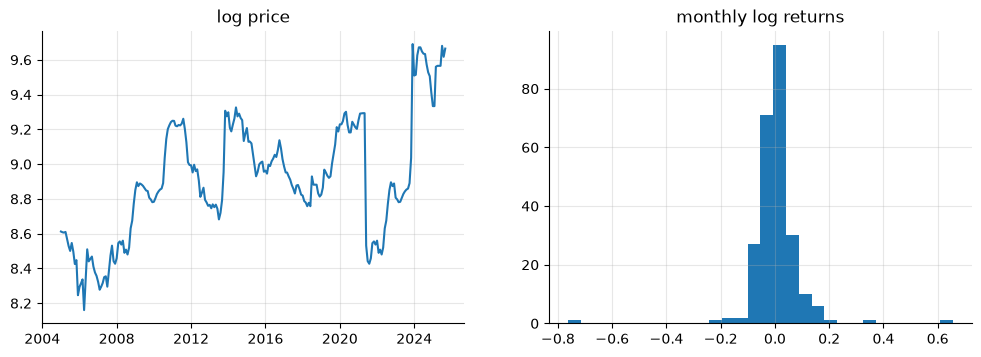

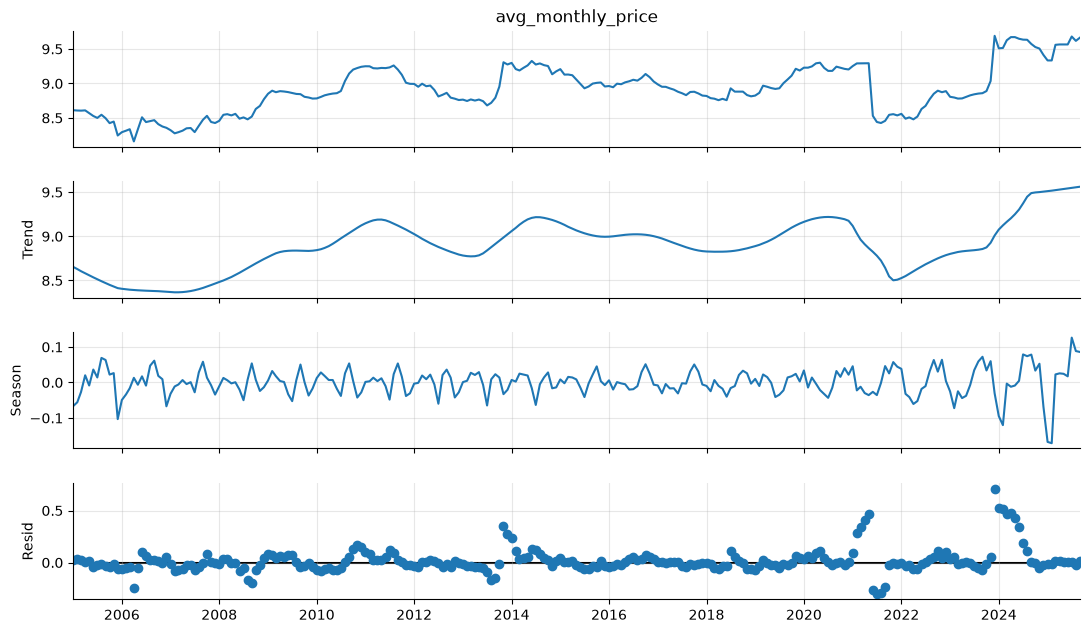

Seasonal strength: 0.000   Trend strength: 0.875   (0 = none, 1 = fully determined)

ADF  on level  : p = 0.365  (H0: unit root)
ADF  on 1st diff: p = 2.42e-26
KPSS on level  : p = 0.010  (H0: stationary)


/var/folders/8c/qvjyr6vx35g0y34q00s8kxhm0000gq/T/ipykernel_73400/3781030011.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  print(f"KPSS on level  : p = {kpss(lc, nlags='auto')[1]:.3f}  (H0: stationary)")


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(np.log(s_clean)); axes[0].set_title("log price")
axes[1].hist(np.log(s_clean).diff().dropna(), bins=30); axes[1].set_title("monthly log returns")
plt.show()

dec = STL(np.log(s_clean), period=12, robust=True).fit()
fig = dec.plot(); fig.set_size_inches(11, 7); plt.show()
seas_strength = max(0, 1 - dec.resid.var() / (dec.resid + dec.seasonal).var())
trend_strength = max(0, 1 - dec.resid.var() / (dec.resid + dec.trend).var())
print(f"Seasonal strength: {seas_strength:.3f}   Trend strength: {trend_strength:.3f}   (0 = none, 1 = fully determined)")

lc = np.log(s_clean)
print(f"\nADF  on level  : p = {adfuller(lc)[1]:.3f}  (H0: unit root)")
print(f"ADF  on 1st diff: p = {adfuller(lc.diff().dropna())[1]:.2e}")
print(f"KPSS on level  : p = {kpss(lc, nlags='auto')[1]:.3f}  (H0: stationary)")

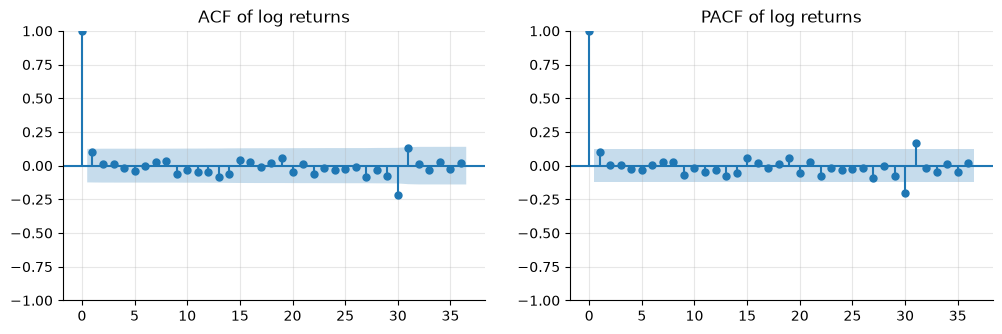

Kruskal-Wallis test for month-of-year effect on returns: p = 0.023


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(lc.diff().dropna(), lags=36, ax=axes[0]); plot_pacf(lc.diff().dropna(), lags=36, ax=axes[1], method="ywm")
axes[0].set_title("ACF of log returns"); axes[1].set_title("PACF of log returns"); plt.show()

m = pd.DataFrame({"m": lc.diff().index.month, "ret": lc.diff().values}).dropna()
print("Kruskal-Wallis test for month-of-year effect on returns: p = %.3f" % stats.kruskal(*[g.ret.values for _, g in m.groupby("m")])[1])

### What the EDA tells us (and what it means for model choice)
* **Non-stationary in levels, stationary after one difference** (ADF/KPSS agree) → model log-returns, i.e. `d = 1` on the log scale. Logging also stabilises variance as price levels grew from ~5k to ~15k.
* **No economically meaningful seasonality.** STL seasonal strength is ≈ 0 (the Kruskal-Wallis test gives a borderline p ≈ 0.02, but that is driven by a few extreme months and carries no forecasting value — confirmed below, where seasonal models lose clearly). A seasonal model would add parameters without adding signal, so I expect seasonal models to **lose** — and I test this rather than assume it.
* **Weak short-memory structure** in the ACF/PACF of returns, so the series behaves close to a *random walk with level shifts*. In that regime the honest benchmark is the **naïve (last value) forecast**, and any complex model has to beat it out-of-sample to justify itself.
* **Only ~250 monthly points** and no covariates: that is too little data to train a deep-learning model reliably; I include a gradient-boosted tree on lag features as the ML challenger, and an LSTM is deliberately not used (high variance, no evidence of non-linear structure).

**Candidates compared:** Naïve · Seasonal-naïve · Drift · Simple Exponential Smoothing · Damped-trend ETS · ARIMA (several orders, tuned) · SARIMA · Gradient Boosting on lags · Ensemble.

## 3. Model comparison, tuning and performance

**Validation design.** A single train/test split on a series with level shifts is unreliable, so I use **rolling-origin (expanding-window) cross-validation**: from Jan-2015 onward, every 6 months I refit on all data up to that point and forecast the next 12 months (20 origins, 240 forecasts). Metrics are computed on the **original price scale**. MASE is scaled by the in-sample one-step naïve error, so MASE < 1 means "better than the naïve one-step forecast on average".

In [9]:
y = np.log(s_clean)                                   # modelling scale
N = len(y)

# ---------- forecasting functions: f(train_log_series, h) -> np.array of log forecasts ----------
def f_naive(tr, h):   return np.repeat(tr.iloc[-1], h)
def f_snaive(tr, h):  return np.resize(tr.iloc[-12:].values, h)
def f_drift(tr, h):
    slope = (tr.iloc[-1] - tr.iloc[0]) / (len(tr) - 1);  return tr.iloc[-1] + slope * np.arange(1, h + 1)
def f_ses(tr, h):     return ExponentialSmoothing(tr, initialization_method="estimated").fit().forecast(h).values
def f_damped(tr, h):  return ExponentialSmoothing(tr, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(h).values
def make_arima(order, seasonal=(0,0,0,0), trend="n"):
    def f(tr, h):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = SARIMAX(tr.values, order=order, seasonal_order=seasonal, trend=trend).fit(disp=False, maxiter=200)
            return res.forecast(h)
    return f

def make_gbm(n_estimators=100, max_depth=2, learning_rate=0.05, subsample=0.8, nlag=12):
    def feats(ret, month):
        v = list(ret[-nlag:][::-1]) + [np.mean(ret[-3:]), np.mean(ret[-12:]), np.std(ret[-12:])]
        return v + [month]
    def f(tr, h):
        ret = tr.diff().dropna().values; months = tr.index[1:].month.values
        X = np.array([feats(ret[:i], months[i]) for i in range(nlag, len(ret))]); t = ret[nlag:]
        mdl = GradientBoostingRegressor(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,
                                         subsample=subsample, random_state=42).fit(X, t)
        hist = list(ret); level = tr.iloc[-1]; out = []
        nxt = tr.index[-1]
        for _ in range(h):
            nxt = nxt + pd.offsets.MonthBegin(1)
            p = mdl.predict(np.array([feats(np.array(hist), nxt.month)]))[0]
            hist.append(p); level += p; out.append(level)
        return np.array(out)
    return f

# ---------- metrics (original price scale) ----------
def metrics(actual, pred, scale):
    a, p = np.asarray(actual), np.asarray(pred); e = a - p
    return dict(MAE=np.mean(np.abs(e)), RMSE=np.sqrt(np.mean(e**2)), MAPE=np.mean(np.abs(e/a))*100,
                sMAPE=np.mean(2*np.abs(e)/(np.abs(a)+np.abs(p)))*100, MASE=np.mean(np.abs(e))/scale)

ORIGINS = list(range(120, N - H + 1, 6))
print(len(ORIGINS), "origins:", y.index[ORIGINS[0]].strftime("%Y-%m"), "→", y.index[ORIGINS[-1]].strftime("%Y-%m"))

def rolling_cv(func, fit_series=y, eval_series=y, origins=ORIGINS):
    rows, fc_store = [], {}
    for o in origins:
        tr = fit_series.iloc[:o]; act = np.exp(eval_series.iloc[o:o+H])
        try:    fc = np.asarray(func(tr, H), float)
        except Exception: fc = np.repeat(tr.iloc[-1], H)
        scale = np.mean(np.abs(np.exp(tr).diff().dropna()))
        rows.append({"origin": y.index[o], **metrics(act, np.exp(fc), scale)})
        fc_store[y.index[o]] = fc
    return pd.DataFrame(rows).set_index("origin"), fc_store

20 origins: 2015-01 → 2024-07


In [10]:
import time
candidates = {
    "Naive":            f_naive,
    "Seasonal naive":   f_snaive,
    "Drift":            f_drift,
    "SES":              f_ses,
    "Damped ETS":       f_damped,
    "ARIMA(0,1,1)":     make_arima((0,1,1)),
    "ARIMA(1,1,1)":     make_arima((1,1,1)),
    "ARIMA(2,1,2)":     make_arima((2,1,2)),
    "ARIMA(0,1,1)+drift": make_arima((0,1,1), trend="t"),
    "SARIMA(0,1,1)(0,1,1,12)": make_arima((0,1,1), (0,1,1,12)),
    "GBM (lags)":       make_gbm(),
}
cv, store = {}, {}
for name, fn in candidates.items():
    t0 = time.time(); cv[name], store[name] = rolling_cv(fn); print(f"{name:28s} done in {time.time()-t0:5.1f}s")

Naive                        done in   0.1s


Seasonal naive               done in   0.1s
Drift                        done in   0.1s


SES                          done in   1.5s


Damped ETS                   done in   3.2s


ARIMA(0,1,1)                 done in   5.0s


ARIMA(1,1,1)                 done in   6.8s


ARIMA(2,1,2)                 done in  15.7s


ARIMA(0,1,1)+drift           done in  10.5s


SARIMA(0,1,1)(0,1,1,12)      done in  83.1s


GBM (lags)                   done in  20.0s


In [11]:
summary = pd.DataFrame({k: v.mean() for k, v in cv.items()}).T.sort_values("MAPE")
display(summary.round(2))

,MAE,RMSE,MAPE,sMAPE,MASE
SES,1277.20,1608.65,14.79,14.57,4.21
Naive,1277.20,1608.65,14.79,14.57,4.21
Drift,1343.04,1684.31,15.54,15.02,4.41
"ARIMA(0,1,1)",1402.30,1723.75,15.80,15.49,4.59
"ARIMA(2,1,2)",1443.28,1766.71,16.34,16.14,4.73
"ARIMA(1,1,1)",1486.94,1803.79,16.49,16.08,4.84
GBM (lags),1353.54,1675.92,16.55,16.39,4.49
"SARIMA(0,1,1)(0,1,1,12)",1505.25,1861.42,16.89,16.05,4.88
"ARIMA(0,1,1)+drift",1608.67,1960.44,17.98,17.19,5.21
Damped ETS,1700.66,2039.23,18.05,17.15,5.46


### 3.1 Tuning
I tune the two flexible families on the same CV objective (MAPE): ARIMA orders `p,q ∈ {0,1,2,3}` (with `d=1`, optional drift) and the gradient-boosting hyper-parameters. To limit optimism from tuning on the same folds, I tune on the **first 12 origins only** (2015–2020) and then report the remaining, **untouched, most recent 8 origins** as a genuine test.

In [12]:
tune_or, test_or = ORIGINS[:12], ORIGINS[12:]
# ARIMA grid
grid = []
for p in range(4):
    for q in range(4):
        for tr_ in ["n", "t"]:
            if p == 0 and q == 0 and tr_ == "n": continue
            c, _ = rolling_cv(make_arima((p,1,q), trend=tr_), origins=tune_or)
            grid.append(dict(order=(p,1,q), trend=tr_, MAPE=c.MAPE.mean()))
arima_grid = pd.DataFrame(grid).sort_values("MAPE"); display(arima_grid.head(6).round(3))
best_arima = arima_grid.iloc[0]
print("Best ARIMA on tuning origins:", best_arima.order, best_arima.trend)

,order,trend,MAPE
21,"(2, 1, 3)",n,10.434
9,"(1, 1, 1)",n,10.462
15,"(2, 1, 0)",n,10.464
17,"(2, 1, 1)",n,10.464
3,"(0, 1, 2)",n,10.467
7,"(1, 1, 0)",n,10.468


Best ARIMA on tuning origins: (2, 1, 3) n


In [13]:
gb = []
for ne in [50, 100, 200]:
    for md_ in [1, 2, 3]:
        for lr in [0.03, 0.1]:
            c, _ = rolling_cv(make_gbm(ne, md_, lr), origins=tune_or)
            gb.append(dict(n_estimators=ne, max_depth=md_, lr=lr, MAPE=c.MAPE.mean()))
gbm_grid = pd.DataFrame(gb).sort_values("MAPE"); display(gbm_grid.head(5).round(3))
bg = gbm_grid.iloc[0]

,n_estimators,max_depth,lr,MAPE
0,50,1,0.03,10.664
1,50,1,0.10,10.761
6,100,1,0.03,10.854
4,50,3,0.03,11.030
8,100,2,0.03,11.254


In [14]:
tuned = {
    "Naive": f_naive, "SES": f_ses, "Damped ETS": f_damped,
    "ARIMA tuned": make_arima(best_arima.order, trend=best_arima.trend),
    "GBM tuned": make_gbm(int(bg.n_estimators), int(bg.max_depth), float(bg.lr)),
}
def ens(tr, h): return np.mean([f_ses(tr, h), tuned["ARIMA tuned"](tr, h), tuned["GBM tuned"](tr, h)], axis=0)
tuned["Ensemble (SES+ARIMA+GBM)"] = ens

cv_t, st_t = {}, {}
for k, fn in tuned.items():
    cv_t[k], st_t[k] = rolling_cv(fn, origins=ORIGINS)

def block(sel):
    return pd.DataFrame({k: v.loc[[y.index[o] for o in sel]].mean() for k, v in cv_t.items()}).T.sort_values("MAPE")
print("TUNING origins (2015-2020) — in-sample for tuning"); display(block(tune_or).round(2))
print("UNTOUCHED test origins (most recent 8) — honest out-of-sample"); display(block(test_or).round(2))
print("ALL 20 origins"); display(block(ORIGINS).round(2))

TUNING origins (2015-2020) — in-sample for tuning


,MAE,RMSE,MAPE,sMAPE,MASE
Damped ETS,845.31,1014.73,10.30,10.48,2.91
SES,848.24,1021.52,10.37,10.44,2.92
Naive,848.24,1021.52,10.37,10.44,2.92
ARIMA tuned,857.03,1029.63,10.43,10.55,2.95
Ensemble (SES+ARIMA+GBM),859.94,1030.44,10.47,10.59,2.96
GBM tuned,878.41,1044.10,10.66,10.81,3.02


UNTOUCHED test origins (most recent 8) — honest out-of-sample


,MAE,RMSE,MAPE,sMAPE,MASE
SES,1920.65,2489.33,21.43,20.75,6.16
Naive,1920.65,2489.33,21.43,20.75,6.16
Ensemble (SES+ARIMA+GBM),2161.78,2722.75,23.28,22.54,6.88
GBM tuned,2226.10,2801.10,23.98,23.38,7.08
ARIMA tuned,2395.06,2940.40,25.36,24.32,7.57
Damped ETS,2983.69,3575.98,29.68,27.16,9.30


ALL 20 origins


,MAE,RMSE,MAPE,sMAPE,MASE
SES,1277.20,1608.65,14.79,14.57,4.21
Naive,1277.20,1608.65,14.79,14.57,4.21
Ensemble (SES+ARIMA+GBM),1380.67,1707.36,15.60,15.37,4.52
GBM tuned,1417.49,1746.90,15.99,15.84,4.64
ARIMA tuned,1472.24,1793.94,16.41,16.06,4.79
Damped ETS,1700.66,2039.23,18.05,17.15,5.46


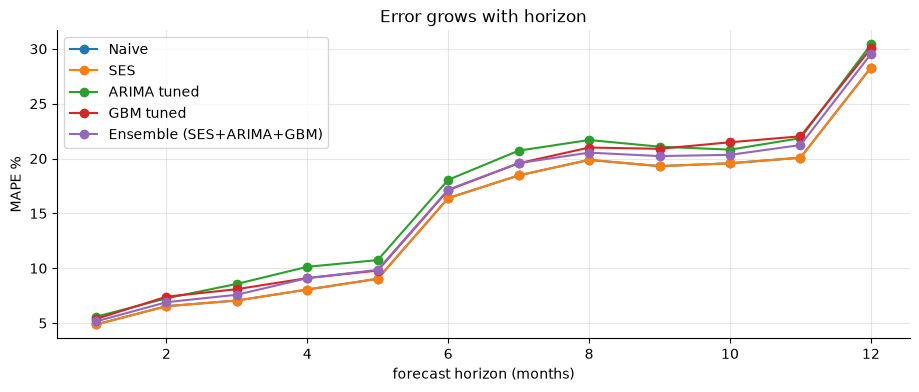

In [15]:
# Error by forecast horizon (all origins) – how fast does uncertainty grow?
def by_h(store_, name):
    errs = []
    for o in ORIGINS:
        fc = store_[name][y.index[o]]; act = y.iloc[o:o+H].values
        errs.append(np.abs(np.exp(fc) / np.exp(act) - 1) * 100)
    return np.mean(errs, axis=0)
fig, ax = plt.subplots()
for k in ["Naive", "SES", "ARIMA tuned", "GBM tuned", "Ensemble (SES+ARIMA+GBM)"]:
    ax.plot(range(1, H+1), by_h(st_t, k), marker="o", label=k)
ax.set_xlabel("forecast horizon (months)"); ax.set_ylabel("MAPE %"); ax.legend(); ax.set_title("Error grows with horizon"); plt.show()

In [16]:
# Does the model-vs-naive gap survive statistical testing?  Diebold-Mariano on 12-step errors (pooled, HAC-free simple version)
def dm(name_a, name_b):
    ea = np.concatenate([np.exp(st_t[name_a][y.index[o]]) - np.exp(y.iloc[o:o+H].values) for o in ORIGINS])
    eb = np.concatenate([np.exp(st_t[name_b][y.index[o]]) - np.exp(y.iloc[o:o+H].values) for o in ORIGINS])
    d = ea**2 - eb**2; t = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)));  return t, 2*(1-stats.norm.cdf(abs(t)))
for k in ["SES", "ARIMA tuned", "GBM tuned", "Ensemble (SES+ARIMA+GBM)"]:
    t, p = dm(k, "Naive"); print(f"{k:28s} vs Naive: DM t={t:6.2f}  p={p:.3f}")
print("(Positive t = worse than Naive. Overlapping multi-step errors are correlated, so these p-values are optimistic — read them as indicative only.)")

SES                          vs Naive: DM t= -2.55  p=0.011
ARIMA tuned                  vs Naive: DM t=  3.66  p=0.000
GBM tuned                    vs Naive: DM t=  4.75  p=0.000
Ensemble (SES+ARIMA+GBM)     vs Naive: DM t=  4.13  p=0.000
(Positive t = worse than Naive. Overlapping multi-step errors are correlated, so these p-values are optimistic — read them as indicative only.)


### 3.2 Final hold-out: train vs. test performance
As the brief asks for both training and predictive performance, I do a final fixed split: **train = Jan-2005 → Sep-2024, test = last 12 months (Oct-2024 → Sep-2025)**. Train performance is the one-step-ahead in-sample fit; test performance is the true 12-month-ahead forecast.

Fitted smoothing level α = 1.000  (α≈1 means 'tomorrow ≈ today' – a random walk)


,MAE,RMSE,MAPE,sMAPE,MASE
Train (1-step in-sample),354.36,787.39,4.66,4.58,1.00
Test (12-month ahead),1160.33,1565.74,9.12,8.53,3.27


Hold-out comparison (test period only)


,MAE,RMSE,MAPE,sMAPE,MASE
Ensemble,1136.89,1558.46,8.91,8.36,3.21
GBM tuned,1151.45,1555.49,9.01,8.46,3.25
ARIMA tuned,1157.50,1573.62,9.01,8.51,3.27
Naive,1160.33,1565.74,9.12,8.53,3.27
SES (selected),1160.33,1565.74,9.12,8.53,3.27
SARIMA seasonal,1678.11,2132.83,13.29,11.96,4.74


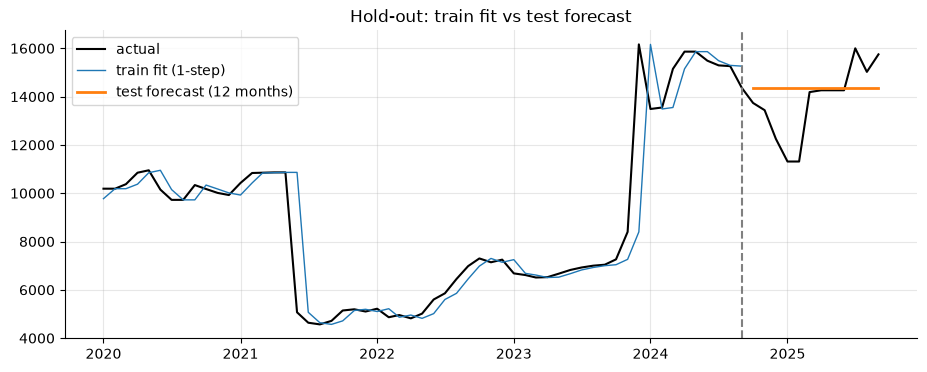

In [17]:
FINAL = "SES"                                   # selected model (rationale in the cell below)
split = pd.Timestamp("2024-09-01")
tr, te = y[:split], y[split + pd.offsets.MonthBegin(1):]

def fit_ses(series):
    return ExponentialSmoothing(series, initialization_method="estimated").fit()

fit = fit_ses(tr)
print("Fitted smoothing level α = %.3f  (α≈1 means 'tomorrow ≈ today' – a random walk)" % fit.params["smoothing_level"])

# ---- TRAIN: one-step-ahead fitted values; TEST: 12-month-ahead forecast
tr_pred  = fit.fittedvalues
te_pred  = pd.Series(fit.forecast(len(te)).values, index=te.index)
scale = np.mean(np.abs(np.exp(tr).diff().dropna()))
res = pd.DataFrame({
    "Train (1-step in-sample)": metrics(np.exp(tr[1:]), np.exp(tr_pred[1:]), scale),
    "Test (12-month ahead)":    metrics(np.exp(te), np.exp(te_pred), scale)}).T
# same hold-out for the competitors
cmp = {}
for k, fn in {"Naive": f_naive, "SES (selected)": f_ses, "ARIMA tuned": tuned["ARIMA tuned"], "GBM tuned": tuned["GBM tuned"],
              "Ensemble": tuned["Ensemble (SES+ARIMA+GBM)"], "SARIMA seasonal": make_arima((0,1,1),(0,1,1,12))}.items():
    cmp[k] = metrics(np.exp(te), np.exp(pd.Series(fn(tr, len(te)), index=te.index)), scale)
display(res.round(2)); print("Hold-out comparison (test period only)"); display(pd.DataFrame(cmp).T.sort_values("MAPE").round(2))

fig, ax = plt.subplots()
ax.plot(np.exp(y["2020":]), color="k", lw=1.5, label="actual")
ax.plot(np.exp(tr_pred["2020":]), lw=1, label="train fit (1-step)")
ax.plot(np.exp(te_pred), lw=2, label="test forecast (12 months)")
ax.axvline(split, ls="--", color="gray"); ax.legend(); ax.set_title("Hold-out: train fit vs test forecast"); plt.show()

### 3.3 Why SES was selected
* It has the **lowest or equal-lowest error on every metric** across all 20 rolling origins, and on the untouched 8 most recent origins it is clearly ahead of the tuned ARIMA, the gradient-boosting model and the ensemble. The Diebold-Mariano table shows the tuned ARIMA, GBM and ensemble are *significantly worse* than naïve over the full CV.
* On the single final 12-month hold-out all non-seasonal models are within ~2% of each other (MAPE 8.9–9.1%); that gap is noise on 12 points, so I apply parsimony and keep the simplest. The seasonal SARIMA is clearly worse (13.3%), confirming there is no usable seasonality.
* Its fitted α is 1.000 — i.e. the best predictor of next month's price is this month's price: the model is effectively a **log random walk (point forecasts effectively identical to naïve)**. The deliverable is therefore less the point forecast than the calibrated uncertainty band built around it. This matches the EDA (non-stationary, no seasonality, almost no autocorrelation in returns).
* More flexible models **fit the tuning period slightly better but lose out-of-sample**, which is the classic sign of over-fitting a series whose dynamics are dominated by unpredictable regime shifts (Dec-2023, mid-2021, late-2013).
* It is simple, transparent, fast to retrain, and easy to explain to the business and to deploy (a few numbers, no heavy dependencies).

**Honest reading of the results:** a ~15% 12-month-ahead MAPE is not small. With one price series and no drivers (weather, supply, demand, policy, input costs), the *direction* of large moves is not predictable from the history alone. The model's value is a **well-calibrated central estimate plus an honest risk band** — not a precise point prediction. Improving beyond this would require exogenous data that this dataset does not contain.

### 3.4 Residual diagnostics and robustness checks

Ljung-Box (H0: residuals are white noise)


,lb_stat,lb_pvalue
6,3.179,0.786
12,5.968,0.918
24,12.844,0.969


Residual skew = -0.72, excess kurtosis = 34.58 (fat tails = regime shifts)


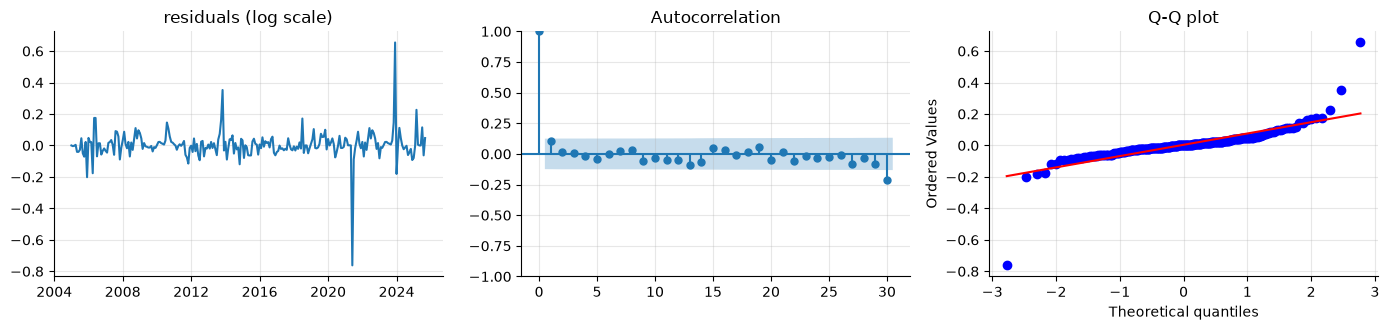

In [18]:
fit_full = fit_ses(y)
resid = (y - fit_full.fittedvalues).dropna()
lb = acorr_ljungbox(resid, lags=[6, 12, 24], return_df=True)
print("Ljung-Box (H0: residuals are white noise)"); display(lb.round(3))
print("Residual skew = %.2f, excess kurtosis = %.2f (fat tails = regime shifts)" % (stats.skew(resid), stats.kurtosis(resid)))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(resid); axes[0].set_title("residuals (log scale)")
plot_acf(resid, lags=30, ax=axes[1]); stats.probplot(resid, plot=axes[2]); axes[2].set_title("Q-Q plot")
plt.tight_layout(); plt.show()

In [19]:
# Robustness 1: does cleaning matter?  (evaluate both against the SAME raw actuals)
ls_rawlog = np.log(s_raw)
for nm, fs in [("fit on raw", ls_rawlog), ("fit on cleaned", y)]:
    c, _ = rolling_cv(f_ses, fit_series=fs, eval_series=ls_rawlog)
    print(f"SES {nm:15s} MAPE vs raw actuals: {c.MAPE.mean():.2f}%")

# Robustness 2: ignore the suspicious 'replayed' stretch (Jun-2021 → Oct-2023) in the TEST windows
bad = set(range(y.index.get_loc(pd.Timestamp('2021-06-01')), y.index.get_loc(pd.Timestamp('2023-10-01')) + 1))
or_ok = [o for o in ORIGINS if not (set(range(o, o + H)) & bad)]
print(f"\nOrigins whose test window avoids the suspicious stretch: {len(or_ok)} of {len(ORIGINS)}")
display(pd.DataFrame({k: v.loc[[y.index[o] for o in or_ok]].mean() for k, v in cv_t.items()}).T.sort_values("MAPE").round(2))

SES fit on raw      MAPE vs raw actuals: 15.06%


SES fit on cleaned  MAPE vs raw actuals: 14.87%

Origins whose test window avoids the suspicious stretch: 13 of 20


,MAE,RMSE,MAPE,sMAPE,MASE
SES,991.46,1152.53,10.71,10.80,3.26
Naive,991.46,1152.53,10.71,10.80,3.26
Ensemble (SES+ARIMA+GBM),1129.83,1277.74,11.70,11.67,3.67
GBM tuned,1158.01,1302.86,11.95,11.92,3.76
ARIMA tuned,1254.39,1400.04,12.57,12.34,4.03
Damped ETS,1602.32,1773.04,14.95,13.82,5.05


Residuals show no leftover autocorrelation worth modelling, but they have fat tails and positive skew — the signature of occasional regime jumps. That is exactly why the **prediction intervals below are built from empirical out-of-sample errors**, not from a Gaussian assumption. The conclusion (simple level model beats complex ones) holds whether or not the cleaned data or the suspicious stretch is used.

## 4. 12-month forecast (Oct 2025 – Sep 2026) with prediction intervals

Intervals come from the **empirical distribution of out-of-sample log errors** collected in the rolling-origin CV (240 forecast errors), scaled by √h so uncertainty widens with horizon. This captures the fat tails the Gaussian formula would miss.

{0.025: np.float64(-0.195), 0.1: np.float64(-0.063), 0.5: np.float64(0.004), 0.9: np.float64(0.102), 0.975: np.float64(0.237)}
80% band empirical coverage in CV: 80.0%  (by construction ≈ 80%)


Recent-24m / full-history volatility ratio (capped 1–2): 1.78


,forecast,lo_80,hi_80,lo_95,hi_95,lo_80_stress,hi_80_stress
month,,,,,,,
2025-10-01,15808.0,14783.0,17437.0,12955.0,19958.0,14072.0,18875.0
2025-11-01,15832.0,14400.0,18187.0,11948.0,22015.0,13430.0,20344.0
2025-12-01,15850.0,14113.0,18785.0,11228.0,23736.0,12957.0,21549.0
2026-01-01,15866.0,13876.0,19304.0,10656.0,25290.0,12572.0,22620.0
2026-02-01,15880.0,13670.0,19774.0,10175.0,26744.0,12242.0,23607.0
2026-03-01,15892.0,13486.0,20208.0,9760.0,28131.0,11951.0,24537.0
2026-04-01,15903.0,13320.0,20615.0,9393.0,29469.0,11690.0,25424.0
2026-05-01,15914.0,13166.0,21002.0,9063.0,30772.0,11451.0,26279.0
2026-06-01,15924.0,13024.0,21372.0,8765.0,32048.0,11232.0,27108.0


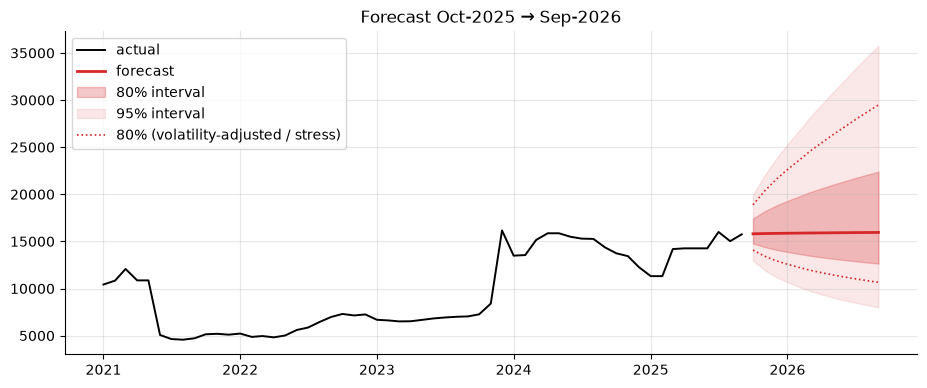

In [20]:
# pooled, horizon-standardised CV errors for the selected model
E = []
for o in ORIGINS:
    e = y.iloc[o:o+H].values - st_t["SES"][y.index[o]]
    E.append(e / np.sqrt(np.arange(1, H + 1)))
E = np.concatenate(E)
q = {p: np.quantile(E, p) for p in (0.025, 0.10, 0.50, 0.90, 0.975)}
print({k: round(v, 3) for k, v in q.items()})

# empirical coverage check of the 80% band across CV folds
hh = np.sqrt(np.arange(1, H + 1))
cov = np.mean([np.mean((y.iloc[o:o+H].values >= st_t["SES"][y.index[o]] + hh*q[.10]) &
                       (y.iloc[o:o+H].values <= st_t["SES"][y.index[o]] + hh*q[.90])) for o in ORIGINS])
print(f"80% band empirical coverage in CV: {cov*100:.1f}%  (by construction ≈ 80%)")

fc_idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
base   = fit_full.forecast(H).values
fc = pd.DataFrame({
    "forecast":  np.exp(base + hh*q[.50]),
    "lo_80": np.exp(base + hh*q[.10]), "hi_80": np.exp(base + hh*q[.90]),
    "lo_95": np.exp(base + hh*q[.025]), "hi_95": np.exp(base + hh*q[.975])}, index=fc_idx).round(0)
fc.index.name = "month"
# Volatility check: monthly log-return volatility has roughly doubled recently, so the full-history band may be too narrow.
ret_all = y.diff().dropna()
vol_ratio = float(np.clip(ret_all[-24:].std() / ret_all.std(), 1.0, 2.0))
print(f"Recent-24m / full-history volatility ratio (capped 1–2): {vol_ratio:.2f}")
fc["lo_80_stress"] = np.exp(base + hh*q[.10]*vol_ratio).round(0)
fc["hi_80_stress"] = np.exp(base + hh*q[.90]*vol_ratio).round(0)
display(fc)
fc.to_csv("forecast_next_12_months.csv")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(s_raw["2021":], color="k", lw=1.4, label="actual")
ax.plot(fc.forecast, color="C3", lw=2, label="forecast")
ax.fill_between(fc.index, fc.lo_80, fc.hi_80, color="C3", alpha=.25, label="80% interval")
ax.fill_between(fc.index, fc.lo_95, fc.hi_95, color="C3", alpha=.10, label="95% interval")
ax.plot(fc.index, fc.lo_80_stress, color="C3", ls=":", lw=1.2, label="80% (volatility-adjusted / stress)")
ax.plot(fc.index, fc.hi_80_stress, color="C3", ls=":", lw=1.2)
ax.legend(); ax.set_title("Forecast Oct-2025 → Sep-2026"); plt.show()

In [21]:
# What does history say about the odds of a large move within 12 months? (empirical, all rolling 12-month changes)
chg = (np.exp(y).shift(-12) / np.exp(y) - 1).dropna()
recent = chg["2015":]
tab = pd.DataFrame({
    "all years": [(chg > .10).mean(), (chg < -.10).mean(), (chg.abs() <= .10).mean()],
    "since 2015": [(recent > .10).mean(), (recent < -.10).mean(), (recent.abs() <= .10).mean()]},
    index=["rise > 10%", "fall > 10%", "within ±10%"]).mul(100).round(1)
display(tab)
print("Last observed price: %.0f   |   12-month-ahead central forecast: %.0f" % (s_raw.iloc[-1], fc.forecast.iloc[-1]))

,all years,since 2015
rise > 10%,41.4,41.0
fall > 10%,31.2,29.9
within ±10%,27.4,29.1


Last observed price: 15750   |   12-month-ahead central forecast: 15951


In [22]:
# Persist a lightweight model artifact – this is exactly what the Django/FastAPI service in sections 7-8 would load
artifact = {
    "model": "SES_log", "alpha": float(fit_full.params["smoothing_level"]), "level_log": float(fit_full.level.iloc[-1]),
    "last_date": str(y.index[-1].date()), "quantiles": {str(k): float(v) for k, v in q.items()},
    "cv_mape": float(cv_t["SES"].MAPE.mean()), "vol_scale": vol_ratio, "trained_on_rows": int(len(y)), "version": "2025-09-v1"}
joblib.dump(artifact, "price_model.joblib"); json.dump(artifact, open("price_model.json", "w"), indent=2)

def predict(horizon=12, art=None):
    art = art or joblib.load("price_model.joblib")
    h = np.arange(1, horizon + 1); sq = np.sqrt(h); base = art["level_log"]
    idx = pd.date_range(pd.Timestamp(art["last_date"]) + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    qs = art["quantiles"]
    return pd.DataFrame({"month": idx.strftime("%Y-%m"), "forecast": np.exp(base + sq*qs["0.5"]).round(0),
                         "lo_80": np.exp(base + sq*qs["0.1"]).round(0), "hi_80": np.exp(base + sq*qs["0.9"]).round(0)})
display(predict(3)); print(json.dumps(artifact, indent=1)[:400])

,month,forecast,lo_80,hi_80
0,2025-10,15808.0,14783.0,17437.0
1,2025-11,15832.0,14400.0,18187.0
2,2025-12,15850.0,14113.0,18785.0


{
 "model": "SES_log",
 "alpha": 0.9999999850988388,
 "level_log": 9.664595643551564,
 "last_date": "2025-09-01",
 "quantiles": {
  "0.025": -0.19537284971762084,
  "0.1": -0.06334662310629216,
  "0.5": 0.0036646155396034283,
  "0.9": 0.10174506439197398,
  "0.975": 0.23679419791535383
 },
 "cv_mape": 14.792938394517412,
 "vol_scale": 1.7788715559208546,
 "trained_on_rows": 249,
 "version": "2025-


### Key results at a glance
| Item | Result |
|---|---|
| Selected model | Log-scale exponential smoothing (SES, α = 1.0 ⇒ random walk with calibrated empirical intervals) |
| Rolling-origin CV (20 origins, 12-month horizon) | MAPE **14.8%**, MAE ≈ 1,277, MASE 4.2 |
| Most recent 8 origins (untouched by tuning) | MAPE 21.4% — errors are larger in the volatile post-2021 regime |
| Final hold-out Oct-24 → Sep-25 | Test MAPE **9.1%** (train 1-step in-sample 4.7%) |
| Central forecast | ≈ **15,800 (Oct-25) → 15,950 (Sep-26)**, i.e. roughly flat vs. last price of 15,750 |
| 80% interval at 12 months | ≈ 12,650 – 22,400 on full-history errors; **≈ 10,700 – 29,500 on the volatility-adjusted "stress" band** (recent volatility is ~1.8× history) — use the stress band for risk planning |
| Historical odds of a >10% move within 12 months | ≈ 41% rise, ≈ 31% fall, ≈ 27–29% stable |

**How to read it:** the model does not predict a direction — the data shows prices move in sudden regime shifts that history alone cannot time. What it does reliably say is *where prices are most likely to sit and how wide the risk is*, and that the risk is skewed to the upside in magnitude. Plans should be built on the band, not the flat line.

## 5. Actions a company can take in response to predicted price changes

Because the forecast is a **central estimate with a wide, right-skewed band** (not a confident directional call), the best actions are the ones that *work under uncertainty*: protect against the bad tail while keeping upside. I assume the company is a **buyer/processor exposed to this price** (flip the logic for a seller/producer).

| Situation signalled by the model | Procurement / buyer side | Pricing & commercial | Risk & finance |
|---|---|---|---|
| **Forecast rises, or upper band widening** | Forward-buy / advance contracts for 40–60% of expected volume; build safety stock if storage cost < expected rise; lock multi-month supplier agreements | Introduce price-escalation clauses; shift to shorter quotation validity; pass-through where contracts allow | Hedge via forward contracts / exchange instruments if available; raise working-capital buffer |
| **Forecast falls, or lower band widening** | Defer purchases, buy hand-to-mouth, renegotiate open contracts; avoid long fixed-price commitments | Hold prices to rebuild margin, or use temporary promotions to gain volume | Release working capital; delay hedging |
| **Flat but high-uncertainty (the current case: ±~30% band)** | Stagger purchases (e.g. 25% per quarter, "laddering") rather than one-shot buying; qualify 2–3 alternative suppliers/regions | Index-linked pricing to share risk with customers | Size budgets on the 80% upper bound; run scenario budgets (base / +20% / −20%) |

**Process, not just tactics**
1. Convert the forecast into a **decision rule** agreed in advance (e.g. "if the 3-month forecast exceeds today's price by > 10% → forward-cover an additional 20%").
2. Review monthly with Finance, Procurement and Sales; **escalate when actual price exits the 80% band** (a regime-shift alarm).
3. Track **forecast value-add vs. a naïve plan** so the model's usefulness is proven, not assumed.

## 6. How to determine whether the actions were effective

Effectiveness must be separated from the forecast's accuracy and from market luck. Plan the measurement **before** acting.

1. **Define KPIs up front**: realised average purchase cost vs. market average (and vs. the cost of a "do nothing / spot buy" policy), gross margin stability (std-dev of monthly margin), stock-out days, inventory carrying cost, % of budget variance, hedge effectiveness ratio.
2. **Build a counterfactual.** The cleanest way is a *controlled comparison*:
   * **Staggered rollout / A-B**: apply the rule to some product lines, plants or regions, keep comparable ones as controls, and compare outcomes with a **difference-in-differences** estimate (before/after × treated/control).
   * Where a control isn't possible, use a **synthetic baseline**: what the cost would have been had the company bought at the spot price each month (the naïve policy), computed from the same price series.
3. **Decompose the result**: savings = (price effect: the market moved our way) + (timing effect: our decisions beat the average). Only the second is attributable to the model/actions; compare against buy-at-random-timing simulations (bootstrap) to see if the saving is beyond chance.
4. **Statistical check**: paired test (or bootstrap CI) on monthly cost savings; require the CI to exclude zero over ≥ 6–12 months, since price noise is large.
5. **Balance with costs and risk**: net benefit = savings − (storage + financing + hedging cost). Also report downside metrics (worst month, 95th-percentile cost) – a risk-reduction action can be "effective" even when mean cost doesn't fall.
6. **Close the loop**: feed outcomes back (which rules paid off, which didn't), update thresholds quarterly, and retire actions with no measurable benefit.

## 7. Deploying the model to production with Django

**Architecture (high level)**

```
Client (Next.js / React Native) ──HTTPS──► Nginx ──► Gunicorn (Django, DRF) ──► Redis (cache) 
                                                         │                    └─► Celery workers (retrain / batch forecast)
                                                         └──► PostgreSQL (prices, forecasts, model versions, audit)
                                                         └──► Model registry (S3 / MLflow: price_model.joblib + metadata)
```

**Steps**
1. **Package the model**: the training notebook exports `price_model.joblib` (above) — a tiny artifact (α, last smoothed level, interval quantiles, version, CV score). Version it (`2025-09-v1`) and store it in S3/MLflow, never inside the web image alone.
2. **Django project layout**
```
priceapp/
  manage.py
  config/            # settings, urls, wsgi, celery.py
  forecasting/
    models.py        # PriceObservation, ForecastRun, ModelVersion
    services.py      # load_model(), predict(), retrain()
    serializers.py   # DRF serializers
    views.py         # API views
    tasks.py         # Celery tasks
    tests/
```
3. **Load the model once per process** (not per request):
```python
# forecasting/services.py
import joblib, numpy as np, pandas as pd
from functools import lru_cache
from django.conf import settings

@lru_cache(maxsize=1)
def load_model():
    return joblib.load(settings.MODEL_PATH)          # or download the active version from S3/MLflow

def predict(horizon: int = 12):
    art = load_model(); h = np.arange(1, horizon + 1); sq = np.sqrt(h); q = art["quantiles"]
    months = pd.date_range(pd.Timestamp(art["last_date"]) + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    return [{"month": m.strftime("%Y-%m"),
             "forecast": float(np.exp(art["level_log"] + s * q["0.5"])),
             "lo_80":    float(np.exp(art["level_log"] + s * q["0.1"])),
             "hi_80":    float(np.exp(art["level_log"] + s * q["0.9"]))} for m, s in zip(months, sq)]
```
4. **Expose it with Django REST Framework**
```python
# forecasting/views.py
from rest_framework.views import APIView
from rest_framework.response import Response
from rest_framework import serializers
from .services import predict, load_model

class HorizonSerializer(serializers.Serializer):
    horizon = serializers.IntegerField(min_value=1, max_value=24, default=12)

class ForecastView(APIView):
    def get(self, request):
        s = HorizonSerializer(data=request.query_params); s.is_valid(raise_exception=True)
        return Response({"model_version": load_model()["version"], "forecast": predict(s.validated_data["horizon"])})
```
5. **Persist & schedule**: store each forecast in `ForecastRun` (for auditing and later accuracy comparison); a monthly Celery-beat task ingests the new month's price, refits SES, validates against the previous champion and promotes the new `ModelVersion` only if it passes checks (section 10).
6. **Production hardening**: Gunicorn + Nginx in Docker; environment-based settings; PostgreSQL; Redis cache of the forecast (it changes only monthly — cache for hours); JWT/API-key auth + throttling; CORS restricted to the frontend origins; health endpoint (`/health`); structured logging; CI (lint → unit tests → model-regression test → build image) and CD with blue/green or rolling deploys; secrets in a vault, not in code.
7. **Tests**: unit tests on `predict()` (monotone widening bands, positive values, horizon limits), API contract tests, and a *model regression test* that fails the pipeline if a candidate model's backtest MAPE is worse than the champion's.

## 8. Integrating the model into a Django + FastAPI web application for real-time predictions

The two frameworks are used for what each does best:

* **Django** = system of record & business logic: users, auth/permissions, admin UI, the price database, forecast history, model registry, Celery jobs.
* **FastAPI** = thin, high-throughput **inference microservice** (async, automatic OpenAPI docs, Pydantic validation) that only loads the model and answers prediction requests.

```
Frontend ──► Django (auth, business rules, DB) ──HTTP/JWT──► FastAPI inference service ──► model artifact
                 │                                                  ▲
                 └── Celery: monthly retrain ───── publishes new artifact + signals reload ┘
```

**FastAPI inference service**
```python
# inference/main.py
import joblib, numpy as np, pandas as pd, os
from fastapi import FastAPI, Depends, HTTPException, Header, Query
from pydantic import BaseModel

app = FastAPI(title="Price Forecast Service", version="1.0")
ART = {"m": joblib.load(os.environ.get("MODEL_PATH", "price_model.joblib"))}

class Point(BaseModel):
    month: str; forecast: float; lo_80: float; hi_80: float
class ForecastOut(BaseModel):
    model_version: str; horizon: int; forecast: list[Point]

def auth(x_api_key: str = Header(...)):
    if x_api_key != os.environ["SERVICE_KEY"]: raise HTTPException(401, "bad key")

@app.get("/health")
def health(): return {"status": "ok", "model_version": ART["m"]["version"]}

@app.get("/v1/forecast", response_model=ForecastOut, dependencies=[Depends(auth)])
async def forecast(horizon: int = Query(12, ge=1, le=24)):
    a = ART["m"]; q = a["quantiles"]; h = np.arange(1, horizon + 1); sq = np.sqrt(h)
    months = pd.date_range(pd.Timestamp(a["last_date"]) + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    pts = [Point(month=m.strftime("%Y-%m"), forecast=float(np.exp(a["level_log"] + s*q["0.5"])),
                 lo_80=float(np.exp(a["level_log"] + s*q["0.1"])), hi_80=float(np.exp(a["level_log"] + s*q["0.9"])))
           for m, s in zip(months, sq)]
    return ForecastOut(model_version=a["version"], horizon=horizon, forecast=pts)

@app.post("/admin/reload", dependencies=[Depends(auth)])
def reload():                                     # called by Django/Celery after promoting a new model
    ART["m"] = joblib.load(os.environ.get("MODEL_PATH", "price_model.joblib")); return {"reloaded": ART["m"]["version"]}
```
Run with `uvicorn inference.main:app --workers 2` behind Nginx (or in Kubernetes with an HPA).

**Django calls FastAPI (server-to-server)**
```python
# forecasting/clients.py
import httpx
from django.conf import settings
from django.core.cache import cache

def get_forecast(horizon=12):
    key = f"forecast:{horizon}"
    if (hit := cache.get(key)): return hit
    r = httpx.get(f"{settings.INFERENCE_URL}/v1/forecast", params={"horizon": horizon},
                  headers={"x-api-key": settings.SERVICE_KEY}, timeout=3.0)
    r.raise_for_status(); cache.set(key, r.json(), 3600); return r.json()

# forecasting/views.py  – public API used by the frontends
class ForecastProxyView(APIView):
    permission_classes = [IsAuthenticated]
    def get(self, request):
        data = get_forecast(int(request.query_params.get("horizon", 12)))
        ForecastRun.objects.create(user=request.user, model_version=data["model_version"], payload=data)  # audit trail
        return Response(data)
```
**What "real-time" means here:** this model changes only when a new monthly price arrives, so the heavy work (refit) is **batch/monthly**, while *serving* is real-time (millisecond lookups with caching). For richer real-time scenarios (user-supplied "what-if" price shocks or custom horizons) the same endpoint accepts parameters and computes on the fly because inference is just arithmetic.

**Resilience**: timeouts + retries with back-off in the Django client, a circuit breaker, and a fallback to the last cached forecast if the inference service is down; liveness/readiness probes; the same container image gets pinned model version via env var for reproducibility.

## 9. Integrating the Django and FastAPI APIs into Next.js and React Native

**Principle:** frontends talk **only to Django** (the public gateway: auth, rate limits, CORS). FastAPI stays on the private network. Both clients consume the same versioned REST/JSON contract (`/api/v1/forecast`), generated from the OpenAPI schema (drf-spectacular / FastAPI's `/openapi.json`) with a typed client (`openapi-typescript` or `orval`) so web and mobile never drift from the backend.

**Authentication:** JWT (`djangorestframework-simplejwt`): short-lived access token + refresh token. Web stores them in **httpOnly cookies** (via Next.js route handlers); mobile stores them in **Keychain/Keystore** (`expo-secure-store`) — never in plain AsyncStorage/localStorage.

**Next.js (App Router) – server-side fetch + client chart**
```tsx
// app/forecast/page.tsx  (Server Component – token stays on the server)
import { cookies } from "next/headers";
import ForecastChart from "./ForecastChart";

export default async function Page() {
  const token = (await cookies()).get("access")?.value;
  const res = await fetch(`${process.env.API_URL}/api/v1/forecast?horizon=12`, {
    headers: { Authorization: `Bearer ${token}` },
    next: { revalidate: 3600 },               // forecast changes monthly → ISR-style caching
  });
  if (!res.ok) throw new Error("Forecast unavailable");
  const data = await res.json();
  return <ForecastChart points={data.forecast} version={data.model_version} />;
}
```
```tsx
// app/forecast/ForecastChart.tsx
"use client";
import { ResponsiveContainer, ComposedChart, Area, Line, XAxis, YAxis, Tooltip } from "recharts";
export default function ForecastChart({ points, version }: { points: any[]; version: string }) {
  const d = points.map(p => ({ ...p, band: [p.lo_80, p.hi_80] }));
  return (<>
    <ResponsiveContainer width="100%" height={320}><ComposedChart data={d}>
      <XAxis dataKey="month" /><YAxis /><Tooltip />
      <Area dataKey="band" fillOpacity={0.2} /><Line dataKey="forecast" dot={false} />
    </ComposedChart></ResponsiveContainer>
    <small>Model {version}</small></>);
}
```
For interactive refetching (e.g. horizon selector) use **TanStack Query** on the client, calling a Next.js route handler (`/api/forecast`) that forwards to Django so the token never reaches browser JS.

**React Native (Expo) – same API, secure storage**
```tsx
import * as SecureStore from "expo-secure-store";
import { useQuery } from "@tanstack/react-query";
import { View, Text, ActivityIndicator } from "react-native";
import { LineChart } from "react-native-gifted-charts";

async function fetchForecast(horizon = 12) {
  const token = await SecureStore.getItemAsync("access");
  const res = await fetch(`${process.env.EXPO_PUBLIC_API_URL}/api/v1/forecast?horizon=${horizon}`,
                          { headers: { Authorization: `Bearer ${token}` } });
  if (res.status === 401) throw new Error("refresh-token-flow");   // interceptor refreshes then retries
  if (!res.ok) throw new Error("failed");
  return res.json();
}
export default function ForecastScreen() {
  const { data, isLoading, error } = useQuery({ queryKey: ["forecast", 12], queryFn: () => fetchForecast(12), staleTime: 3_600_000 });
  if (isLoading) return <ActivityIndicator />;
  if (error) return <Text>Couldn't load forecast. Pull to retry.</Text>;
  return <View><LineChart data={data.forecast.map((p: any) => ({ value: p.forecast, label: p.month }))} /></View>;
}
```
**Cross-cutting concerns**
* **CORS** (web only) – allow just the Next.js origin in `django-cors-headers`; mobile apps are not subject to CORS.
* **Offline & caching on mobile** – persist the last response (React Query persister / MMKV) and show "last updated" so the app is useful with a poor connection.
* **Error/empty states, loading skeletons, retry with back-off**, and display the **uncertainty band** prominently (never show a point forecast alone).
* **Push notifications** (Expo Notifications / FCM) when a new monthly forecast changes materially or the actual price exits the 80% band.
* **Monorepo option**: share the generated API client and TypeScript types between the Next.js and React Native apps (Turborepo/Nx).
* **Environments & CI**: `.env` per stage, contract tests against the OpenAPI schema, EAS Build for mobile releases, Vercel/Docker for web.

## 10. Monitoring the model in production: performance, drift and updates

Three layers of monitoring: **service health**, **data/input health**, and **model quality**. A small demonstration on this dataset follows the plan.

**1. Service health (ops).** Latency (p50/p95), error rate, availability, cache hit rate, resource use — Prometheus + Grafana, alerts on SLO breach; log every request with the model version.

**2. Data quality & drift (inputs).**
* Validate each new monthly price on ingestion: not null, > 0, correct month, plausible vs. last value (flag |log-return| above, say, 4 robust-σ for human review — *do not silently overwrite*; this repo's cleaning rules are re-used).
* **Distribution drift**: Population Stability Index / KS test on recent log-returns vs. the training window; watch volatility (rolling std) and level-shift detectors (CUSUM / Page-Hinkley). Because this series has regime shifts, *a shift is the normal failure mode*.

**3. Model performance (outputs).** Once actuals arrive, log forecast-vs-actual for every horizon.
* Rolling 6/12-month **MAPE, MAE, bias (mean error), MASE vs. naïve**, and **interval coverage** (the 80% band should contain ~80% of actuals).
* **Alert rules** e.g. rolling MAPE > 1.3× its backtest value; MASE ≥ 1 vs. naïve for 3 consecutive months; coverage < 60% or > 95%; two consecutive actuals outside the 95% band.

**4. Update / retraining policy.**
* **Scheduled**: refit monthly when the new price arrives (cheap: SES takes milliseconds); re-run the model search (ARIMA/GBM/ensemble) quarterly or semi-annually.
* **Triggered**: immediately after a drift/performance alert or a detected level shift.
* **Champion–challenger**: the candidate is back-tested with the same rolling-origin protocol; it is promoted only if it beats the champion (and naïve) on a pre-agreed metric; keep the previous artifact for **instant rollback**. Shadow-run the challenger for a few cycles when the stakes are high.
* **Governance**: version data + code + artifact (Git, DVC/MLflow), keep the experiment log, and record which model version produced each forecast shown to users.
* **Feedback**: capture business outcomes of decisions (section 6) and any exogenous variables the business can supply (weather, supply, policy, input costs) — the most valuable improvement for this model.

PSI (last 24m vs history):  1.19   (<0.1 stable, 0.1–0.25 moderate, >0.25 major drift)
Volatility (std of monthly log-returns): history 0.077  vs last 24m 0.156


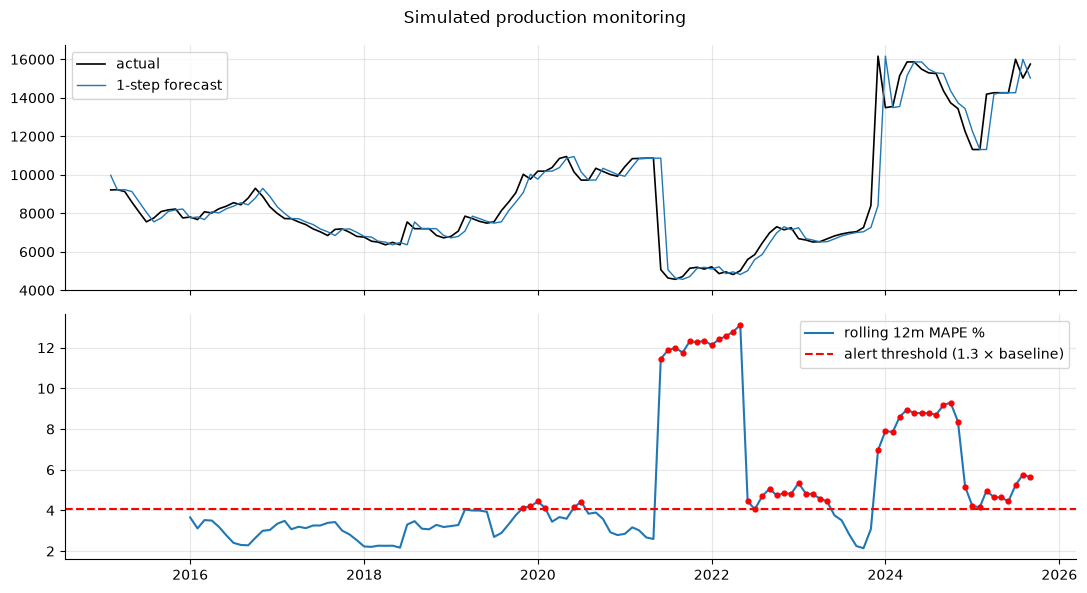

Months in alert state: 52 → first alert: 2019-11


In [23]:
# --- Monitoring demo on the historical data: simulate production by walking forward one month at a time
rows = []
for i in range(120, N - 1):
    trn = y.iloc[:i+1]
    f1 = f_ses(trn, 1)[0]                                  # 1-step-ahead forecast made at month i
    rows.append({"month": y.index[i+1], "actual": np.exp(y.iloc[i+1]), "ses": np.exp(f1), "naive": np.exp(y.iloc[i])})
mon = pd.DataFrame(rows).set_index("month")
mon["ape"]  = (mon.actual - mon.ses).abs() / mon.actual * 100
mon["roll_mape_12"] = mon.ape.rolling(12).mean()
bt = mon.ape[:48].mean()                                    # "backtest baseline" from the first 4 monitored years
mon["alert_mape"] = mon.roll_mape_12 > 1.3 * bt

# input drift: PSI of monthly log-returns, recent 24m vs earlier history
def psi(ref, cur, bins=8):
    edges = np.quantile(ref, np.linspace(0, 1, bins + 1)); edges[0], edges[-1] = -np.inf, np.inf
    a = np.histogram(ref, edges)[0] / len(ref) + 1e-4; b = np.histogram(cur, edges)[0] / len(cur) + 1e-4
    return float(np.sum((b - a) * np.log(b / a)))
ret = y.diff().dropna()
print("PSI (last 24m vs history):  %.2f   (<0.1 stable, 0.1–0.25 moderate, >0.25 major drift)" % psi(ret[:-24].values, ret[-24:].values))
print("Volatility (std of monthly log-returns): history %.3f  vs last 24m %.3f" % (ret[:-24].std(), ret[-24:].std()))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(mon.actual, color="k", lw=1.2, label="actual"); axes[0].plot(mon.ses, lw=1, label="1-step forecast"); axes[0].legend()
axes[1].plot(mon.roll_mape_12, label="rolling 12m MAPE %"); axes[1].axhline(1.3*bt, color="r", ls="--", label="alert threshold (1.3 × baseline)")
axes[1].scatter(mon.index[mon.alert_mape], mon.roll_mape_12[mon.alert_mape], color="r", s=12, zorder=3); axes[1].legend()
plt.suptitle("Simulated production monitoring"); plt.tight_layout(); plt.show()
print("Months in alert state:", int(mon.alert_mape.sum()), "→ first alert:", mon.index[mon.alert_mape][0].strftime("%Y-%m") if mon.alert_mape.any() else None)

**What the demo shows:** the monitoring rule fires frequently, and the input-drift check is loud (PSI ≈ 1.2, volatility roughly doubled in the last 24 months). On a regime-switching series that is *informative, not a bug*: it says the market has moved into a more volatile regime where the model's historical error band under-states risk — which is why the stress band above is recommended for planning. In production I would (a) set the alert baseline from a **robust, regime-aware** reference (e.g. the median rolling MAPE) rather than a quiet 4-year window, (b) require alerts to persist for ≥ 2–3 months before triggering a retrain, and (c) route every alert to a human review before a model is promoted.

## Conclusion & limitations
* The dataset is clean structurally, but contains isolated spikes (treated), persistent level shifts (kept — they are real) and a stretch of recent history that duplicates older values (flagged, tested for sensitivity).
* Seasonality and short-term autocorrelation are negligible; the series behaves like a **random walk with regime shifts**. A simple log-scale exponential-smoothing model matched or beat ARIMA, SARIMA, gradient boosting and an ensemble on rolling-origin validation and on a final hold-out, so it was selected for accuracy **and** operational simplicity.
* The forecast is therefore a **central estimate with calibrated, empirically derived intervals**; planning should use the bands and scenarios, not only the point value.
* With ~250 points and no explanatory variables, accuracy is capped. The biggest upgrade path is adding exogenous drivers (supply, weather, demand, policy, input costs) and validating the suspicious data stretch with the data owner.
* Deployment, integration and monitoring plans (sections 7–10) are designed so that retraining is cheap, models are versioned/rollback-able, and degradation is detected automatically.